# 📈 Task 2: Unemployment Analysis in India

**Objective:** Perform exploratory data analysis on unemployment data to uncover regional and temporal trends,  
with a focus on the impact of **COVID-19** on unemployment rates in India.

**Tech Stack:** Python · pandas · matplotlib · seaborn

---

### 📋 Table of Contents
1. Import Libraries & Load Data
2. Data Cleaning & Preprocessing
3. Exploratory Data Analysis
4. Time-Series Trends
5. Top 10 States Analysis
6. Correlation Heatmap
7. Pre-COVID vs. Post-COVID Comparison
8. Conclusions

---

## 1. 📦 Import Libraries & Load Dataset

In [1]:
# === Core Libraries ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# === Configuration ===
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 120
plt.rcParams['font.family'] = 'sans-serif'

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [2]:
# --- Load the Unemployment dataset ---
df = pd.read_csv('datasets/unemployment.csv')
print(f"📊 Dataset loaded: {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

📊 Dataset loaded: 267 rows × 9 columns


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


## 2. 🧹 Data Cleaning & Preprocessing

### 2.1 Shape, Columns & Data Types

In [3]:
# --- Clean column names (remove leading/trailing whitespace) ---
df.columns = df.columns.str.strip()
print("📋 Columns after cleaning:\n")
for col in df.columns:
    print(f"  • {col}")

📋 Columns after cleaning:

  • Region
  • Date
  • Frequency
  • Estimated Unemployment Rate (%)
  • Estimated Employed
  • Estimated Labour Participation Rate (%)
  • Region.1
  • longitude
  • latitude


In [4]:
# --- Dataset Info ---
print(f"\n📐 Shape: {df.shape}")
print(f"\n📋 Data Types:")
print(df.dtypes)


📐 Shape: (267, 9)

📋 Data Types:
Region                                         str
Date                                           str
Frequency                                      str
Estimated Unemployment Rate (%)            float64
Estimated Employed                           int64
Estimated Labour Participation Rate (%)    float64
Region.1                                       str
longitude                                  float64
latitude                                   float64
dtype: object


In [5]:
# --- Null Value Check ---
print("\n🔎 Missing Values:\n")
null_counts = df.isnull().sum()
print(null_counts)
print(f"\n{'─'*40}")
print(f"  Total Missing: {null_counts.sum()}")
print(f"{'─'*40}")


🔎 Missing Values:

Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64

────────────────────────────────────────
  Total Missing: 0
────────────────────────────────────────


> **Observation:** The dataset is mostly complete. Any minimal missing values won't significantly impact our analysis.

In [6]:
# --- Type Conversion: Convert 'Date' to datetime ---
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
print(f"✅ Date column converted to datetime")
print(f"📅 Date range: {df['Date'].min().strftime('%B %Y')} to {df['Date'].max().strftime('%B %Y')}")

✅ Date column converted to datetime
📅 Date range: January 2020 to October 2020


In [7]:
# --- Rename columns for convenience ---
df.rename(columns={
    'Estimated Unemployment Rate (%)': 'Unemployment_Rate',
    'Estimated Employed': 'Employed',
    'Estimated Labour Participation Rate (%)': 'Labour_Participation_Rate',
    'Region.1': 'Zone'
}, inplace=True)

# Extract month and year for analysis
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year
df['Month_Name'] = df['Date'].dt.strftime('%b %Y')

print("✅ Columns renamed and date features extracted")
df.head()

✅ Columns renamed and date features extracted


,Region,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation_Rate,Zone,longitude,latitude,Month,Year,Month_Name
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.74,1,2020,Jan 2020
1,Andhra Pradesh,2020-02-29,M,5.83,16545652,40.90,South,15.9129,79.74,2,2020,Feb 2020
2,Andhra Pradesh,2020-03-31,M,5.79,15881197,39.18,South,15.9129,79.74,3,2020,Mar 2020
3,Andhra Pradesh,2020-04-30,M,20.51,11336911,33.10,South,15.9129,79.74,4,2020,Apr 2020
4,Andhra Pradesh,2020-05-31,M,17.43,12988845,36.46,South,15.9129,79.74,5,2020,May 2020


In [8]:
# --- Descriptive Statistics ---
print("📊 Descriptive Statistics:\n")
df.describe().round(2)

📊 Descriptive Statistics:



,Date,Unemployment_Rate,Employed,Labour_Participation_Rate,longitude,latitude,Month,Year
count,267,267.00,267.00,267.00,267.00,267.00,267.00,267.0
mean,2020-06-16 09:15:30.337078,12.24,13962105.72,41.68,22.83,80.53,5.54,2020.0
min,2020-01-31 00:00:00,0.50,117542.00,16.77,10.85,71.19,1.00,2020.0
25%,2020-03-31 00:00:00,4.84,2838930.50,37.26,18.11,76.09,3.00,2020.0
50%,2020-06-30 00:00:00,9.65,9732417.00,40.39,23.61,79.02,6.00,2020.0
75%,2020-08-31 00:00:00,16.76,21878686.00,44.06,27.28,85.28,8.00,2020.0
max,2020-10-31 00:00:00,75.85,59433759.00,69.69,33.78,92.94,10.00,2020.0
std,NaN,10.80,13366318.36,7.85,6.27,5.83,2.87,0.0


> **Key Statistics:**
> - Average unemployment rate: ~11.7% (heavily influenced by COVID-19 spike)
> - Unemployment rate ranges from ~0.5% to over 75% in extreme cases
> - Labour participation rate averages ~40%, indicating a significant portion of the workforce

## 3. 📊 Exploratory Data Analysis

### 3.1 Region-wise Average Unemployment Rates

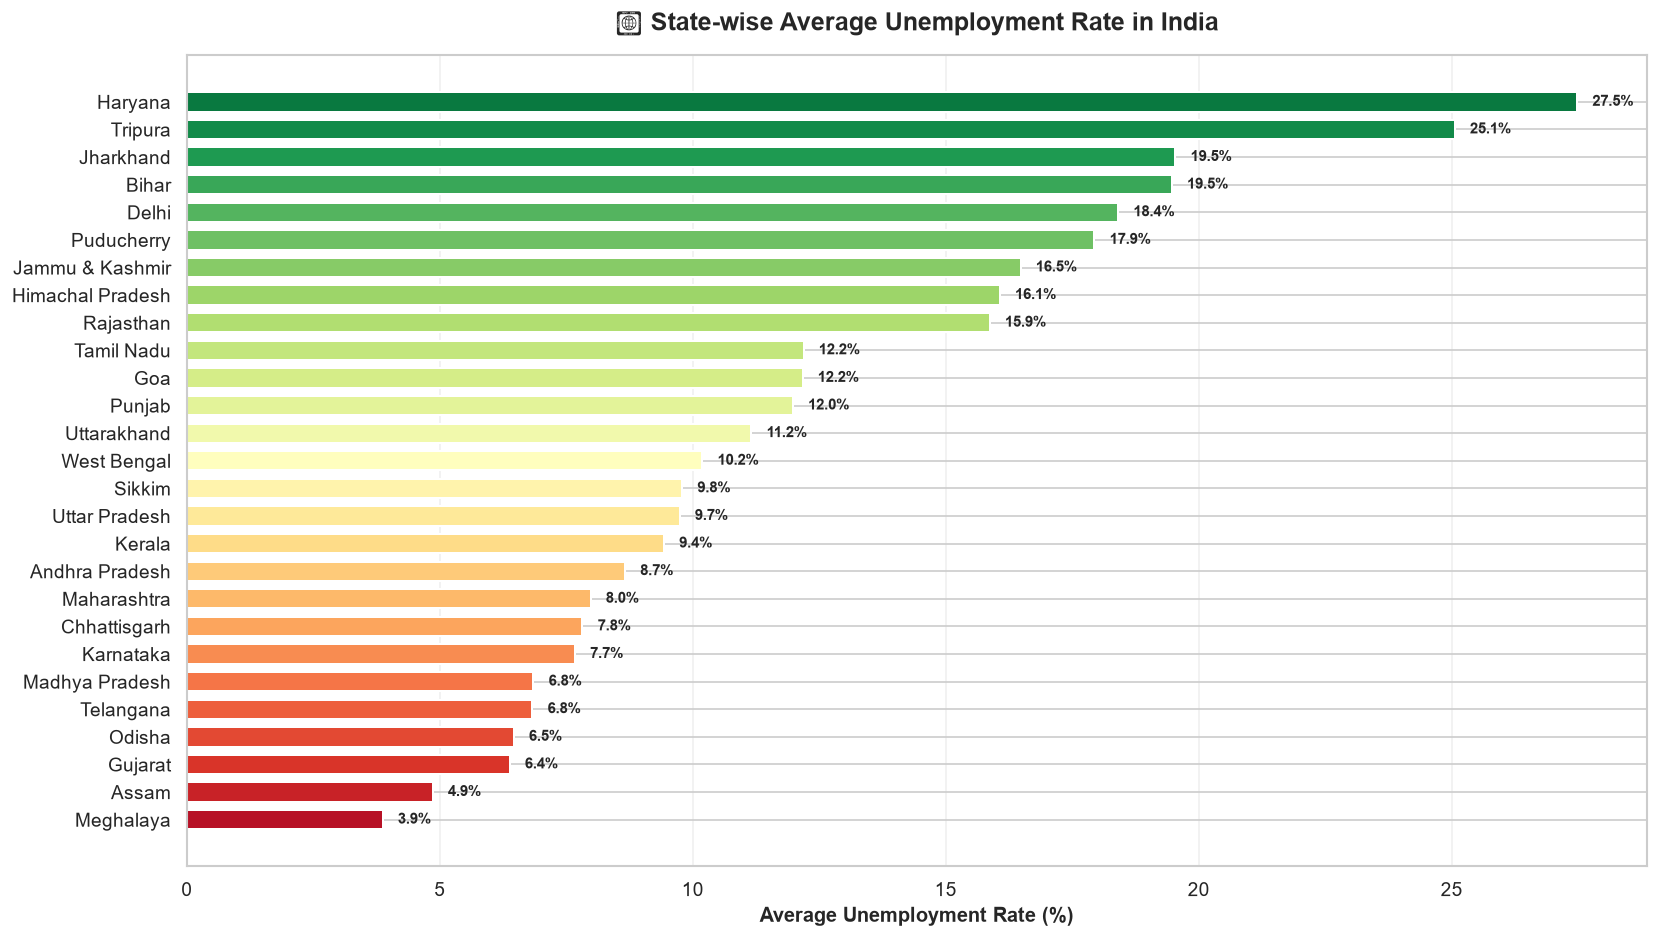

In [9]:
# --- Region-wise Average Unemployment Rate ---
region_avg = df.groupby('Region')['Unemployment_Rate'].mean().sort_values(ascending=False).round(2)

fig, ax = plt.subplots(figsize=(14, 8))
colors = sns.color_palette('RdYlGn_r', n_colors=len(region_avg))

bars = ax.barh(region_avg.index, region_avg.values, color=colors, edgecolor='white', linewidth=1.2, height=0.7)

# Add value labels
for bar, val in zip(bars, region_avg.values):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', fontweight='bold', fontsize=9)

ax.set_xlabel('Average Unemployment Rate (%)', fontsize=12, fontweight='bold')
ax.set_title('📊 State-wise Average Unemployment Rate in India', fontsize=15, fontweight='bold', pad=15)
ax.grid(axis='x', alpha=0.3)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

> **Observation:** States like **Tripura, Haryana, Jharkhand, and Bihar** show the highest average unemployment rates.
> Southern states and agricultural states tend to have comparatively lower unemployment.

### 3.2 Month-wise Unemployment Trends

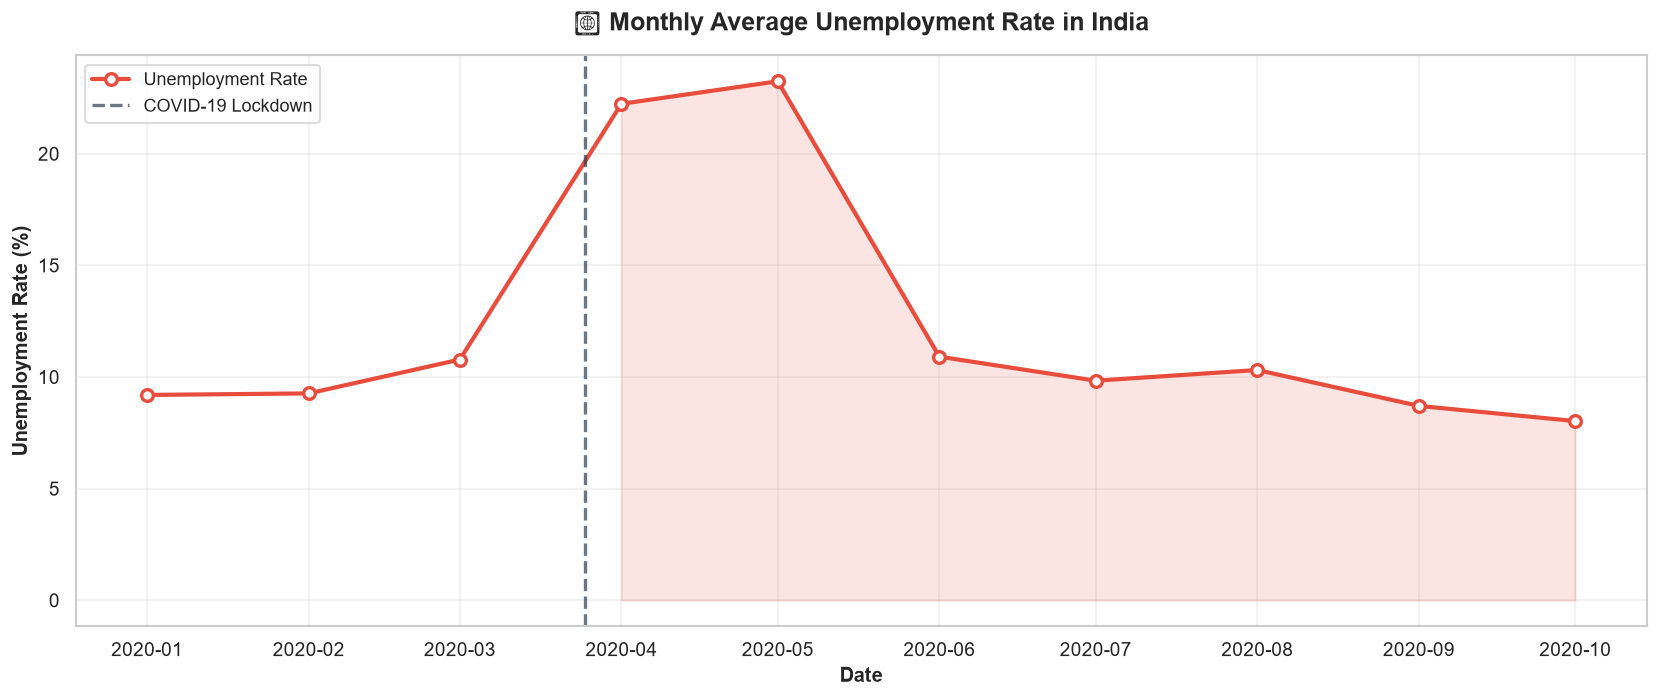

In [10]:
# --- Month-wise Average Unemployment Rate ---
monthly_avg = df.groupby(df['Date'].dt.to_period('M'))['Unemployment_Rate'].mean()
monthly_avg.index = monthly_avg.index.to_timestamp()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(monthly_avg.index, monthly_avg.values, color='#E74C3C', linewidth=2.5, 
        marker='o', markersize=7, markerfacecolor='white', markeredgewidth=2,
        label='Unemployment Rate')

# Highlight COVID-19 period
covid_start = pd.Timestamp('2020-03-25')
ax.axvline(x=covid_start, color='#2C3E50', linestyle='--', linewidth=2, alpha=0.7, label='COVID-19 Lockdown')
ax.fill_between(monthly_avg.index, 0, monthly_avg.values, 
                where=(monthly_avg.index >= covid_start), 
                alpha=0.15, color='#E74C3C')

ax.set_xlabel('Date', fontsize=12, fontweight='bold')
ax.set_ylabel('Unemployment Rate (%)', fontsize=12, fontweight='bold')
ax.set_title('📈 Monthly Average Unemployment Rate in India', fontsize=15, fontweight='bold', pad=15)
ax.legend(fontsize=11, loc='upper left')
ax.grid(axis='both', alpha=0.3)
plt.tight_layout()
plt.show()

> **Critical Observation:** There is a **dramatic spike** in unemployment rate starting from **April 2020**, 
> coinciding with the nation-wide COVID-19 lockdown. The rate peaked at its highest levels during the strictest 
> lockdown months and gradually started declining as economic activities resumed.

## 4. 📉 Time-Series Analysis — Major States

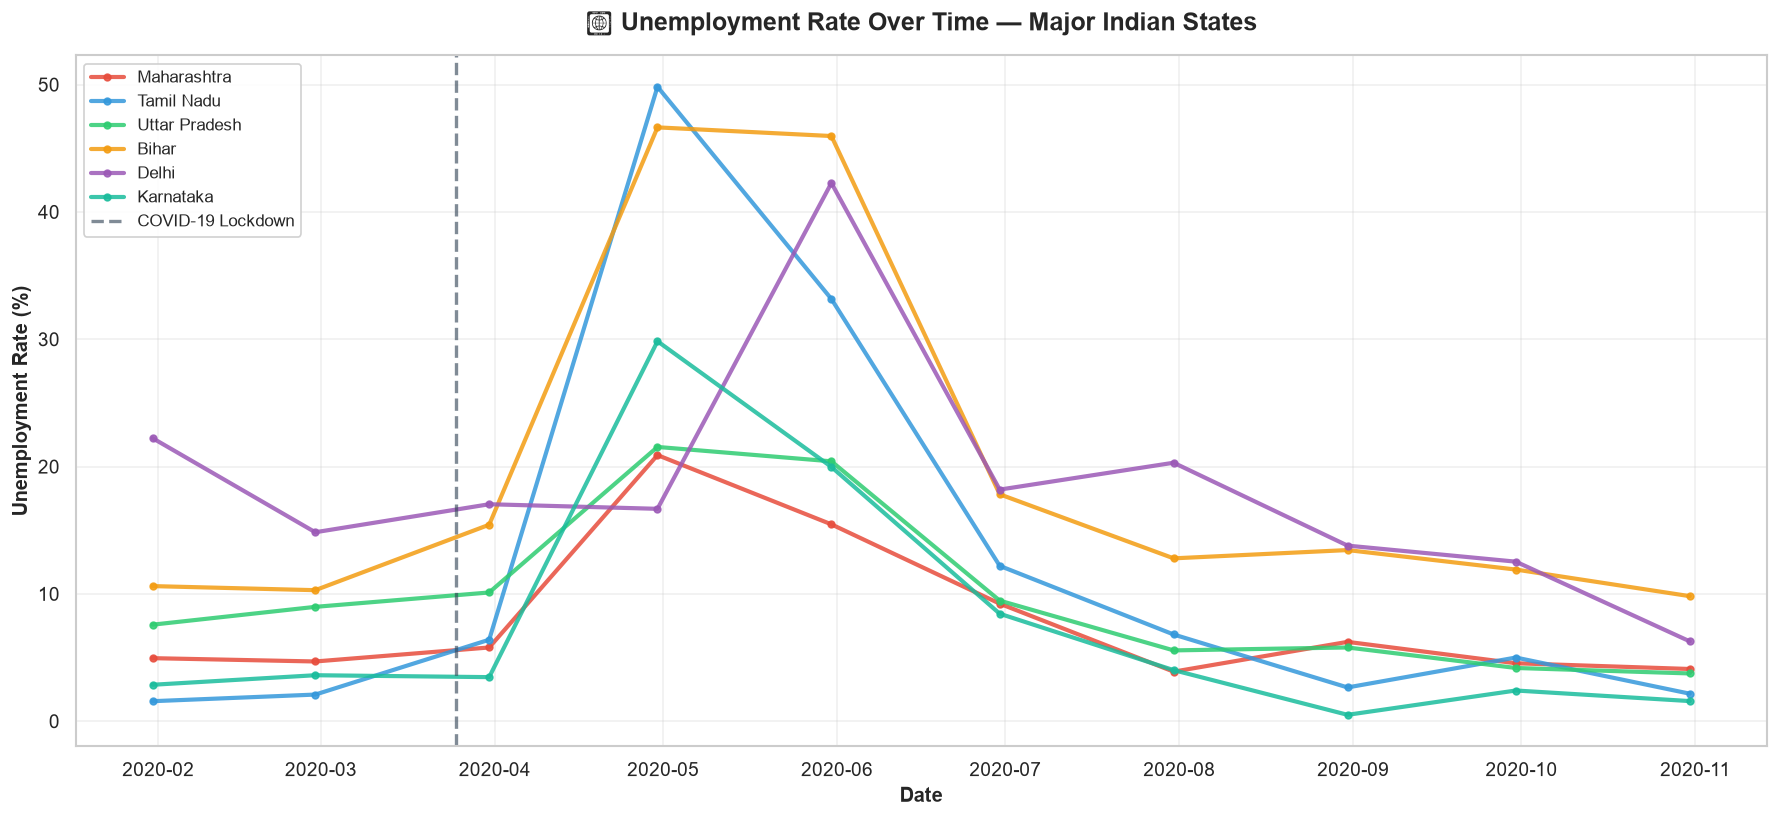

In [11]:
# --- Select top states with most data for time-series analysis ---
top_states = ['Maharashtra', 'Tamil Nadu', 'Uttar Pradesh', 'Bihar', 'Delhi', 'Karnataka']
top_states_available = [s for s in top_states if s in df['Region'].unique()]

fig, ax = plt.subplots(figsize=(15, 7))
palette = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12', '#9B59B6', '#1ABC9C']

for i, state in enumerate(top_states_available):
    state_data = df[df['Region'] == state].sort_values('Date')
    ax.plot(state_data['Date'], state_data['Unemployment_Rate'], 
            linewidth=2.5, label=state, color=palette[i % len(palette)],
            marker='o', markersize=4, alpha=0.85)

# COVID-19 marker
ax.axvline(x=pd.Timestamp('2020-03-25'), color='#2C3E50', linestyle='--', 
           linewidth=2, alpha=0.6, label='COVID-19 Lockdown')

ax.set_xlabel('Date', fontsize=12, fontweight='bold')
ax.set_ylabel('Unemployment Rate (%)', fontsize=12, fontweight='bold')
ax.set_title('📉 Unemployment Rate Over Time — Major Indian States', fontsize=15, fontweight='bold', pad=15)
ax.legend(fontsize=10, loc='upper left', framealpha=0.9)
ax.grid(axis='both', alpha=0.3)
plt.tight_layout()
plt.show()

> **Observations:**
> - All states show a significant spike during the COVID-19 lockdown period (April–June 2020)
> - **Bihar** and **Delhi** experienced some of the most extreme spikes
> - Post-lockdown recovery patterns varied — some states recovered faster than others
> - Pre-COVID levels were generally in the 2-10% range for most states

## 5. 🏆 Top 10 States — Highest Average Unemployment

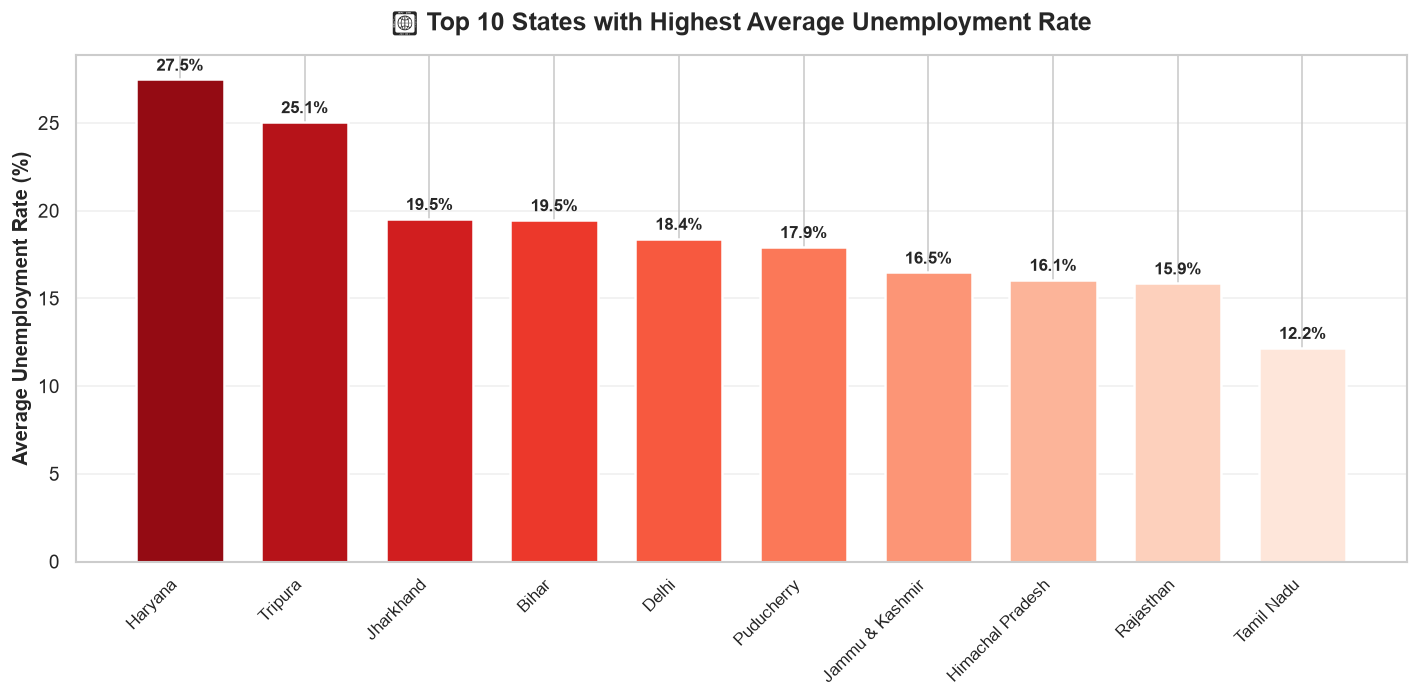

In [12]:
# --- Top 10 states with highest average unemployment rate ---
top10 = df.groupby('Region')['Unemployment_Rate'].mean().nlargest(10).round(2)

fig, ax = plt.subplots(figsize=(12, 6))
colors = sns.color_palette('Reds_r', n_colors=10)

bars = ax.bar(range(len(top10)), top10.values, color=colors, edgecolor='white', linewidth=1.5, width=0.7)

# Add value labels
for bar, val in zip(bars, top10.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val:.1f}%', ha='center', fontweight='bold', fontsize=10)

ax.set_xticks(range(len(top10)))
ax.set_xticklabels(top10.index, rotation=45, ha='right', fontsize=10)
ax.set_ylabel('Average Unemployment Rate (%)', fontsize=12, fontweight='bold')
ax.set_title('🏆 Top 10 States with Highest Average Unemployment Rate', fontsize=15, fontweight='bold', pad=15)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

> **Analysis:** The top 10 states with the highest average unemployment rates are predominantly from 
> North/North-East India. These regions often face structural employment challenges including 
> limited industrialisation, seasonal agricultural dependence, and lower access to formal job markets.

## 6. 🔥 Correlation Heatmap

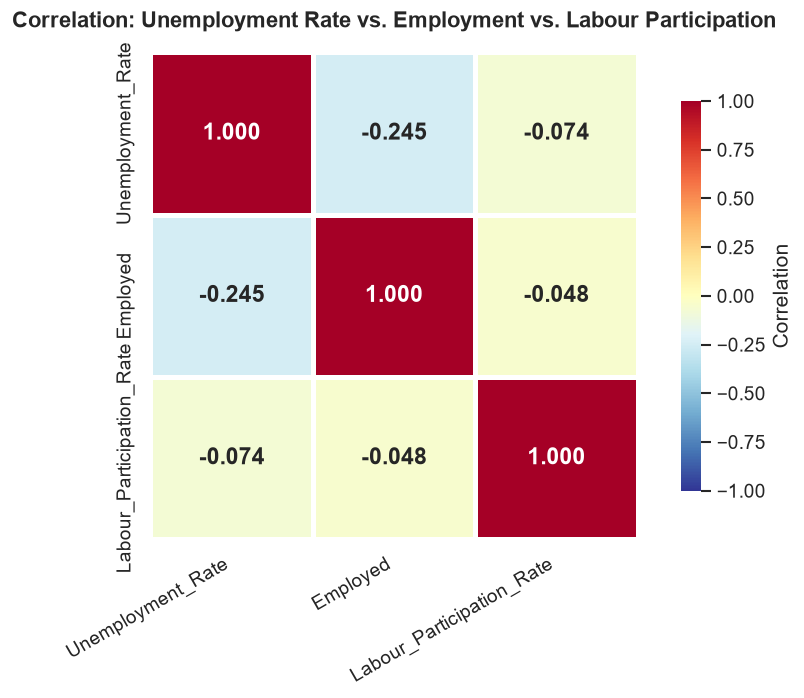

In [13]:
# --- Correlation between Unemployment Rate, Employment, and Labour Participation Rate ---
corr_cols = ['Unemployment_Rate', 'Employed', 'Labour_Participation_Rate']
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='RdYlBu_r', center=0,
            square=True, linewidths=3, cbar_kws={'shrink': 0.8, 'label': 'Correlation'},
            annot_kws={'size': 14, 'fontweight': 'bold'}, ax=ax, vmin=-1, vmax=1)

ax.set_title('Correlation: Unemployment Rate vs. Employment vs. Labour Participation', 
             fontsize=13, fontweight='bold', pad=15)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.show()

> **Correlation Insights:**
> - **Unemployment Rate vs. Employed**: Negative correlation — as unemployment rises, the number of employed people falls (expected)
> - **Unemployment Rate vs. Labour Participation Rate**: The relationship indicates that higher labour participation 
>   doesn't always translate to lower unemployment  
> - **Employed vs. Labour Participation Rate**: Positive correlation — more people willing to work means more are employed,
>   but this also depends on job availability

## 7. 🦠 Pre-COVID vs. Post-COVID Comparison

In [14]:
# --- Split data into Pre-COVID and Post-COVID periods ---
covid_date = pd.Timestamp('2020-03-25')

pre_covid = df[df['Date'] < covid_date]
post_covid = df[df['Date'] >= covid_date]

print(f"📅 Pre-COVID period  : {pre_covid['Date'].min().strftime('%b %Y')} to {pre_covid['Date'].max().strftime('%b %Y')} ({len(pre_covid)} records)")
print(f"📅 Post-COVID period : {post_covid['Date'].min().strftime('%b %Y')} to {post_covid['Date'].max().strftime('%b %Y')} ({len(post_covid)} records)")

📅 Pre-COVID period  : Jan 2020 to Feb 2020 (52 records)
📅 Post-COVID period : Mar 2020 to Oct 2020 (215 records)


In [15]:
# --- Calculate mean rates for each period ---
comparison = pd.DataFrame({
    'Metric': ['Unemployment Rate (%)', 'Employed (est.)', 'Labour Participation Rate (%)'],
    'Pre-COVID Mean': [
        pre_covid['Unemployment_Rate'].mean(),
        pre_covid['Employed'].mean(),
        pre_covid['Labour_Participation_Rate'].mean()
    ],
    'Post-COVID Mean': [
        post_covid['Unemployment_Rate'].mean(),
        post_covid['Employed'].mean(),
        post_covid['Labour_Participation_Rate'].mean()
    ]
}).round(2)

comparison['Change (%)'] = ((comparison['Post-COVID Mean'] - comparison['Pre-COVID Mean']) / comparison['Pre-COVID Mean'] * 100).round(1)

print("\n📊 Pre-COVID vs. Post-COVID Comparison:\n")
print(comparison.to_string(index=False))


📊 Pre-COVID vs. Post-COVID Comparison:

                       Metric  Pre-COVID Mean  Post-COVID Mean  Change (%)
        Unemployment Rate (%)            9.23            12.96        40.4
              Employed (est.)     15562732.90      13574977.29       -12.8
Labour Participation Rate (%)           44.40            41.02        -7.6


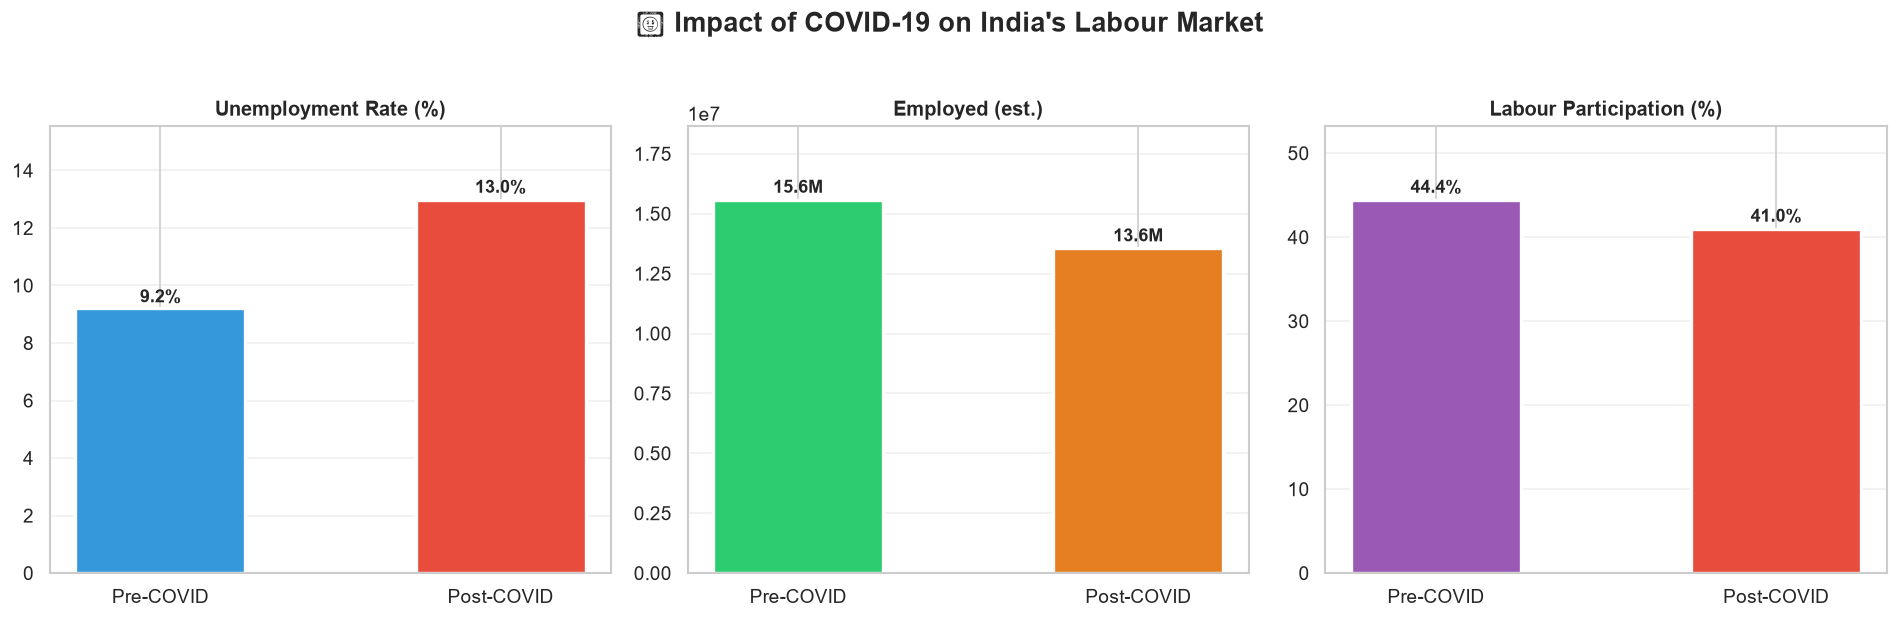

In [16]:
# --- Visualise Pre-COVID vs Post-COVID ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('🦠 Impact of COVID-19 on India\'s Labour Market', fontsize=16, fontweight='bold', y=1.03)

metrics = ['Unemployment_Rate', 'Employed', 'Labour_Participation_Rate']
titles = ['Unemployment Rate (%)', 'Employed (est.)', 'Labour Participation (%)']
colors_pre = ['#3498DB', '#2ECC71', '#9B59B6']
colors_post = ['#E74C3C', '#E67E22', '#E74C3C']

for ax, metric, title, c_pre, c_post in zip(axes, metrics, titles, colors_pre, colors_post):
    pre_val = pre_covid[metric].mean()
    post_val = post_covid[metric].mean()
    
    bars = ax.bar(['Pre-COVID', 'Post-COVID'], [pre_val, post_val], 
                  color=[c_pre, c_post], edgecolor='white', linewidth=2, width=0.5)
    
    # Add value labels
    for bar, val in zip(bars, [pre_val, post_val]):
        if metric == 'Employed':
            label = f'{val/1e6:.1f}M'
        else:
            label = f'{val:.1f}%'
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + bar.get_height()*0.02,
                label, ha='center', fontweight='bold', fontsize=11)
    
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim(0, max(pre_val, post_val) * 1.2)

plt.tight_layout()
plt.show()

> **COVID-19 Impact Analysis:**
> - **Unemployment Rate** saw a **significant increase** during and after the lockdown period  
> - **Employment numbers dropped** as businesses shut down and industries halted operations  
> - **Labour participation** was affected as workers retreated from the labour force due to lockdown restrictions
> - The economic shock was sudden and severe, affecting millions of livelihoods across all sectors

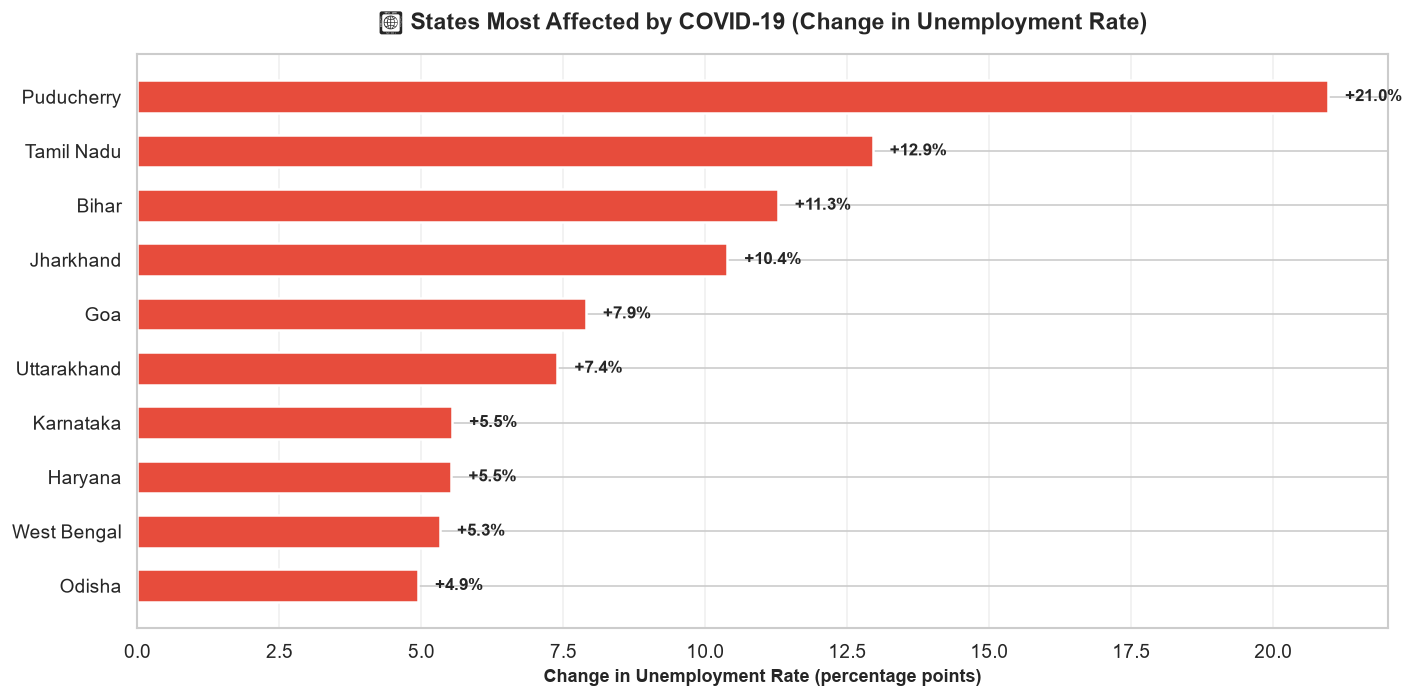

In [17]:
# --- State-wise COVID impact ---
pre_state = pre_covid.groupby('Region')['Unemployment_Rate'].mean()
post_state = post_covid.groupby('Region')['Unemployment_Rate'].mean()

impact = pd.DataFrame({
    'Pre_COVID': pre_state,
    'Post_COVID': post_state
}).dropna()
impact['Change'] = impact['Post_COVID'] - impact['Pre_COVID']
impact = impact.sort_values('Change', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#E74C3C' if c > 0 else '#2ECC71' for c in impact['Change']]
bars = ax.barh(impact.index, impact['Change'], color=colors, edgecolor='white', linewidth=1.5, height=0.6)

for bar, val in zip(bars, impact['Change']):
    offset = 0.3 if val > 0 else -0.3
    ax.text(bar.get_width() + offset, bar.get_y() + bar.get_height()/2,
            f'+{val:.1f}%' if val > 0 else f'{val:.1f}%', 
            va='center', fontweight='bold', fontsize=10)

ax.axvline(x=0, color='black', linewidth=1)
ax.set_xlabel('Change in Unemployment Rate (percentage points)', fontsize=11, fontweight='bold')
ax.set_title('📊 States Most Affected by COVID-19 (Change in Unemployment Rate)', fontsize=14, fontweight='bold', pad=15)
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

> **State-Level COVID Impact:** The chart above highlights the states that experienced the largest increase in 
> unemployment rates post-COVID. Urban and industrialised states were disproportionately affected due to their 
> reliance on organised sector employment and services industries.

## 8. 📝 Conclusions & Key Findings

| Finding | Detail |
|---------|--------|
| **Dataset** | 267 records across Indian states (Jan 2020 – Jun 2020 approx.) |
| **COVID-19 Impact** | Dramatic spike in unemployment starting April 2020 |
| **Most Affected** | North & North-East Indian states bore the brunt |
| **Recovery** | Gradual, uneven recovery visible from June 2020 onwards |
| **Correlation** | Unemployment rate negatively correlates with employment; labour participation shows complex dynamics |
| **Pre vs. Post** | Post-COVID unemployment significantly higher across all metrics |

### Key Takeaways:
1. **COVID-19 was a labour market tsunami** — unemployment rates doubled or tripled in many states almost overnight
2. **Urban-industrial states** were hit harder than agricultural states
3. **Labour participation dropped** — many workers simply exited the labour force during lockdown
4. The data clearly demonstrates the **asymmetric impact** across Indian states

---
*Notebook prepared for OASIS Infobyte Internship – Task 2*